# Step 7 — Game variant: seating

**One dial moved.** The agent is the same, the player count is the same, the reward is the
same, the hyperparameters are the same, and the training budget is the same. The only
difference between the two runs below is **which accuracy sits where around the circle**.

That makes this the cleanest experiment in the folder: if the answer moves, seating moved
it. There is nothing else it could have been.

**The mistake this step is designed to prevent.** The exact profile from folder 02 —
`0.24959 / 0.21073 / 0.17970 / 0.16194 / 0.19804` — is computed for **one specific
arrangement**, accuracies ascending around the circle. Holding a random-seating run
against it would not be a weak comparison, it would be a comparison against the wrong
quantity, and it would make a perfectly correct run look broken. Below, the code itself
refuses to do it.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

from gruel_env import GruelEnv, MISS, SHOOT_LEFT, SHOOT_RIGHT, N_ACTIONS

N_PLAYERS = 5
SEED = 0

torch.set_num_threads(1)

EXACT_RANKED = {0.4: 0.24959, 0.5: 0.21073, 0.6: 0.17970, 0.7: 0.16194, 0.8: 0.19804}
UNIFORM = 1.0 / N_PLAYERS

print("torch", torch.__version__)
print("uniform share, 1/N:", UNIFORM)

torch 2.2.2
uniform share, 1/N: 0.2


## What the two settings actually do

Worth looking at before anything is trained, because it decides what the second run even
measures.

In [2]:
for seating in ["ranked", "random"]:
    look = GruelEnv(n=N_PLAYERS, reward="terminal", seating=seating, seed=1000)
    print(seating + ":")
    arrangements = set()
    for episode in range(6):
        look.reset()
        layout = tuple(round(float(a), 1) for a in look.accuracies)
        arrangements.add(layout)
        print("   ", list(layout))
    print("    distinct arrangements in 6 episodes:", len(arrangements))
    print()

ranked:
    [0.4, 0.5, 0.6, 0.7, 0.8]
    [0.4, 0.5, 0.6, 0.7, 0.8]
    [0.4, 0.5, 0.6, 0.7, 0.8]
    [0.4, 0.5, 0.6, 0.7, 0.8]
    [0.4, 0.5, 0.6, 0.7, 0.8]
    [0.4, 0.5, 0.6, 0.7, 0.8]
    distinct arrangements in 6 episodes: 1

random:
    [0.7, 0.6, 0.5, 0.8, 0.4]
    [0.8, 0.4, 0.5, 0.6, 0.7]
    [0.7, 0.4, 0.5, 0.8, 0.6]
    [0.6, 0.7, 0.8, 0.5, 0.4]
    [0.6, 0.5, 0.4, 0.8, 0.7]
    [0.6, 0.8, 0.5, 0.4, 0.7]
    distinct arrangements in 6 episodes: 6



**`random` re-deals the seats every episode.** So the second run is not a noisier
estimate of the same thing — it is a measurement of a *different* quantity: survival
averaged over all $5! = 120$ arrangements. Only one of those 120 is the arrangement the
exact profile describes.

**The mechanism, predicted before measuring.** Under ranked seating the two best shots
are neighbours, so they are each other's most dangerous opponent and spend their turns
removing each other — which leaves the weakest comparatively alone. That is *why* the
weakest does best. Shuffle the seats and the pairing becomes a lottery: the strongest is
no longer reliably placed next to the second-strongest. So the prediction is that the
weakest player's advantage **weakens or disappears**, and raw accuracy starts to tell.

In [3]:
LOWEST = 0.4
HIGHEST = 0.8

ranked_look = GruelEnv(n=N_PLAYERS, reward="terminal", seating="ranked", seed=1000)
ranked_look.reset()
positions = list(ranked_look.accuracies)
strongest_position = positions.index(max(positions))
left, right = ranked_look.neighbours(strongest_position)
print("under ranked seating, the strongest player sits at position", strongest_position)
print("its neighbours have accuracies:",
      round(float(positions[left]), 1), "and", round(float(positions[right]), 1))
print()
print("so the strongest is adjacent to the second-strongest in EVERY episode.")
print("under random seating that happens by chance, not by construction.")

under ranked seating, the strongest player sits at position 4
its neighbours have accuracies: 0.7 and 0.4

so the strongest is adjacent to the second-strongest in EVERY episode.
under random seating that happens by chance, not by construction.


## The agent, unchanged

Carried forward from step 6 without modification. **The actor's observation is
seating-agnostic** — own accuracy, left, right, fraction alive — so the same network
definition serves both runs and nothing needed adapting for the variant.

In [4]:
OBSERVATION_SIZE = 4
HIDDEN_SIZE = 64


class SharedActorCritic(nn.Module):
    def __init__(self, n_players):
        super().__init__()
        self.n_players = n_players
        self.actor_first = nn.Linear(OBSERVATION_SIZE, HIDDEN_SIZE)
        self.actor_second = nn.Linear(HIDDEN_SIZE, N_ACTIONS)
        critic_input_size = 2 * n_players + n_players
        self.critic_first = nn.Linear(critic_input_size, HIDDEN_SIZE)
        self.critic_second = nn.Linear(HIDDEN_SIZE, 1)
        self.activation = nn.Tanh()

    def action_logits(self, observation):
        hidden = self.activation(self.actor_first(observation))
        return self.actor_second(hidden)

    def value(self, state, agent_one_hot):
        combined = torch.cat([state, agent_one_hot], dim=-1)
        hidden = self.activation(self.critic_first(combined))
        return self.critic_second(hidden).squeeze(-1)


def global_state(game):
    numbers = []
    for position in range(game.n):
        numbers.append(game.accuracies[position])
        if position in game.order:
            numbers.append(1.0)
        else:
            numbers.append(0.0)
    return np.array(numbers, dtype=np.float32)


def one_hot(position, n_players):
    vector = np.zeros(n_players, dtype=np.float32)
    vector[position] = 1.0
    return vector

One thing the critic does get from this, worth noticing: `global_state` reads each
**position's** accuracy, so under random seating its input genuinely changes from episode
to episode. The critic is not being asked to memorise one board — it has to read the one
in front of it.

In [5]:
def collect_batch(model, game, episodes):
    observations = {p: [] for p in range(game.n)}
    actions = {p: [] for p in range(game.n)}
    old_log_probabilities = {p: [] for p in range(game.n)}
    values = {p: [] for p in range(game.n)}
    returns = {p: [] for p in range(game.n)}
    states = {p: [] for p in range(game.n)}
    agent_flags = {p: [] for p in range(game.n)}

    for _ in range(episodes):
        game.reset()
        episode_observations = {p: [] for p in range(game.n)}
        episode_actions = {p: [] for p in range(game.n)}
        episode_log_probabilities = {p: [] for p in range(game.n)}
        episode_values = {p: [] for p in range(game.n)}
        episode_states = {p: [] for p in range(game.n)}
        episode_flags = {p: [] for p in range(game.n)}

        for acting_agent in game.agent_iter():
            observation, reward, termination, truncation, info = game.last()

            # A finished agent is handed to us one last time, so PettingZoo can retire
            # it. Stepping with None is how we say 'nothing to do here'.
            if termination or truncation:
                game.step(None)
                continue

            actor = game.position_of_agent[acting_agent]
            observation_tensor = torch.from_numpy(observation)
            state_array = global_state(game)
            agent_array = one_hot(actor, game.n)

            with torch.no_grad():
                logits = model.action_logits(observation_tensor)
                value = model.value(torch.from_numpy(state_array),
                                    torch.from_numpy(agent_array))

            distribution = torch.distributions.Categorical(logits=logits)
            action = distribution.sample()

            episode_observations[actor].append(observation)
            episode_actions[actor].append(int(action))
            episode_log_probabilities[actor].append(float(distribution.log_prob(action)))
            episode_values[actor].append(float(value))
            episode_states[actor].append(state_array)
            episode_flags[actor].append(agent_array)

            game.step(int(action))

        if len(game.order) == 1:
            winner = game.order[0]
        else:
            winner = None

        for position in range(game.n):
            if position == winner:
                own_return = 1.0
            else:
                own_return = 0.0
            for index in range(len(episode_actions[position])):
                observations[position].append(episode_observations[position][index])
                actions[position].append(episode_actions[position][index])
                old_log_probabilities[position].append(
                    episode_log_probabilities[position][index])
                values[position].append(episode_values[position][index])
                states[position].append(episode_states[position][index])
                agent_flags[position].append(episode_flags[position][index])
                returns[position].append(own_return)

    flat_observations = []
    flat_actions = []
    flat_old_log_probabilities = []
    flat_values = []
    flat_returns = []
    flat_states = []
    flat_flags = []
    for position in range(game.n):
        flat_observations.extend(observations[position])
        flat_actions.extend(actions[position])
        flat_old_log_probabilities.extend(old_log_probabilities[position])
        flat_values.extend(values[position])
        flat_returns.extend(returns[position])
        flat_states.extend(states[position])
        flat_flags.extend(agent_flags[position])

    batch = {
        "observations": torch.tensor(np.array(flat_observations), dtype=torch.float32),
        "actions": torch.tensor(flat_actions, dtype=torch.long),
        "old_log_probabilities": torch.tensor(flat_old_log_probabilities,
                                              dtype=torch.float32),
        "values": torch.tensor(flat_values, dtype=torch.float32),
        "returns": torch.tensor(flat_returns, dtype=torch.float32),
        "states": torch.tensor(np.array(flat_states), dtype=torch.float32),
        "agent_flags": torch.tensor(np.array(flat_flags), dtype=torch.float32),
    }
    return batch

In [6]:
CLIP = 0.2
EPOCHS = 4
MINIBATCH_SIZE = 256
VALUE_COEFFICIENT = 0.5
ENTROPY_COEFFICIENT = 0.01
LEARNING_RATE = 0.003


def ppo_update(model, optimiser, batch, update_rng):
    advantages = batch["returns"] - batch["values"]
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    count = len(batch["actions"])
    order = np.arange(count)

    for epoch in range(EPOCHS):
        update_rng.shuffle(order)
        for start in range(0, count, MINIBATCH_SIZE):
            chunk = order[start:start + MINIBATCH_SIZE]
            index = torch.from_numpy(chunk)

            logits = model.action_logits(batch["observations"][index])
            distribution = torch.distributions.Categorical(logits=logits)
            new_log_probabilities = distribution.log_prob(batch["actions"][index])

            ratio = torch.exp(new_log_probabilities
                              - batch["old_log_probabilities"][index])
            minibatch_advantages = advantages[index]
            unclipped = ratio * minibatch_advantages
            clipped = torch.clamp(ratio, 1 - CLIP, 1 + CLIP) * minibatch_advantages
            policy_loss = -torch.min(unclipped, clipped).mean()

            entropy = distribution.entropy().mean()

            predicted_value = model.value(batch["states"][index],
                                          batch["agent_flags"][index])
            value_loss = ((predicted_value - batch["returns"][index]) ** 2).mean()

            total_loss = (policy_loss
                          + VALUE_COEFFICIENT * value_loss
                          - ENTROPY_COEFFICIENT * entropy)

            optimiser.zero_grad()
            total_loss.backward()
            optimiser.step()

## Measurement, carried forward

Note that `survival_by_accuracy` keys on **the player's accuracy**, never on its
position. Under random seating a position means nothing from one episode to the next, so
keying on position would produce five numbers all near $1/N$ and hide the entire effect.

In [7]:
def make_agent_policy(model):
    def agent_policy(game, actor):
        name = game.agent_of_position[actor]
        observation = game.observe(name)
        with torch.no_grad():
            logits = model.action_logits(torch.from_numpy(observation))
        distribution = torch.distributions.Categorical(logits=logits)
        return int(distribution.sample())
    return agent_policy


def play_episodes(game, policy, episodes):
    records = []
    for _ in range(episodes):
        game.reset()
        decisions = []

        for acting_agent in game.agent_iter():
            observation, reward, termination, truncation, info = game.last()
            if termination or truncation:
                game.step(None)
                continue

            actor = game.position_of_agent[acting_agent]
            action = policy(game, actor)

            # Recorded BEFORE stepping, because a kill contracts the circle.
            left, right = game.neighbours(actor)
            decisions.append({
                "accuracy": round(float(game.accuracies[actor]), 4),
                "action": action,
                "left_accuracy": round(float(game.accuracies[left]), 4),
                "right_accuracy": round(float(game.accuracies[right]), 4),
                "n_alive": game.n_alive(),
            })

            game.step(action)

        if len(game.order) == 1:
            survivor_accuracy = round(float(game.accuracies[game.order[0]]), 4)
        else:
            survivor_accuracy = None

        records.append({
            "survivor_accuracy": survivor_accuracy,
            "stagnated": game.reason == "stagnation",
            "decisions": decisions,
        })
    return records


def stagnation_rate(records):
    stagnated = 0
    for record in records:
        if record["stagnated"]:
            stagnated = stagnated + 1
    return stagnated / len(records)


def survival_by_accuracy(records, accuracies):
    wins = {}
    for accuracy in accuracies:
        wins[accuracy] = 0
    for record in records:
        if record["survivor_accuracy"] is not None:
            wins[record["survivor_accuracy"]] = wins[record["survivor_accuracy"]] + 1
    rates = {}
    for accuracy in sorted(wins):
        rates[accuracy] = wins[accuracy] / len(records)
    return rates


def eligible(decision):
    if decision["action"] == MISS:
        return False        # never fired, so it selected no target
    if decision["n_alive"] <= 2:
        return False        # left and right are the same player
    if decision["left_accuracy"] == decision["right_accuracy"]:
        return False        # neither neighbour is the stronger one
    return True


def chose_stronger(decision):
    if decision["action"] == SHOOT_LEFT:
        chosen = decision["left_accuracy"]
        other = decision["right_accuracy"]
    else:
        chosen = decision["right_accuracy"]
        other = decision["left_accuracy"]
    return chosen > other


def targeting_rate(records, accuracy=None):
    stronger = 0
    decisions = 0
    for record in records:
        for decision in record["decisions"]:
            if accuracy is not None and decision["accuracy"] != accuracy:
                continue
            if not eligible(decision):
                continue
            decisions = decisions + 1
            if chose_stronger(decision):
                stronger = stronger + 1
    if decisions == 0:
        return None, 0, 0
    return stronger / decisions, stronger, decisions


def targeting_by_alive(records):
    stronger_count = {}
    decision_count = {}
    for record in records:
        for decision in record["decisions"]:
            if not eligible(decision):
                continue
            alive_then = decision["n_alive"]
            if alive_then not in decision_count:
                stronger_count[alive_then] = 0
                decision_count[alive_then] = 0
            decision_count[alive_then] = decision_count[alive_then] + 1
            if chose_stronger(decision):
                stronger_count[alive_then] = stronger_count[alive_then] + 1
    rows = {}
    for alive in sorted(decision_count):
        rows[alive] = (stronger_count[alive] / decision_count[alive],
                       stronger_count[alive],
                       decision_count[alive])
    return rows

## The guard: the exact comparison refuses to run on the wrong variant

The README's warning is easy to nod at and then forget three cells later. So it is a
function precondition instead of a note: ask for the exact comparison on a random-seating
run and it declines, and says why.

In [8]:
class WrongVariant(Exception):
    pass


def compare_to_exact(measured, seating):
    """Ratios against the exact profile. Only legitimate for ranked seating."""
    if seating != "ranked":
        raise WrongVariant(
            "the exact profile is computed for accuracies ascending around the circle; "
            "under " + seating + " seating the seats are re-dealt every episode, so the "
            "measurement is an average over all 120 arrangements and the exact numbers "
            "are not its target")
    rows = []
    for accuracy in sorted(measured):
        rows.append((accuracy, measured[accuracy], EXACT_RANKED[accuracy],
                     measured[accuracy] / EXACT_RANKED[accuracy]))
    return rows

## Training: two configurations, three seeds each

Everything below is shared between the two arms except the one keyword argument.

In [9]:
UPDATES = 2000
EPISODES_PER_UPDATE = 96
EVALUATION_EPISODES = 10000
SEEDS = [0, 1, 2]
SEATINGS = ["ranked", "random"]

print("configurations :", SEATINGS)
print("seeds each     :", SEEDS)
print("per run        :", UPDATES * EPISODES_PER_UPDATE, "training episodes,",
      EVALUATION_EPISODES, "measured")
print("total runs     :", len(SEATINGS) * len(SEEDS))

configurations : ['ranked', 'random']
seeds each     : [0, 1, 2]
per run        : 192000 training episodes, 10000 measured
total runs     : 6


## Saving the trained models

Every model this step trains for its results is written to `models/` as two files: the weights
(`<run>.pt`, a PyTorch `state_dict`) and a record of the model (`<run>.json`): its layers and
parameter counts, what its actor and critic see, every training setting and seed, the game it was
trained in, the software versions, and hashes of the weights and of the code that produced them.
Models trained only to check reproducibility are not saved.

**Two hashes, for two jobs.** `weights_sha256` is computed from the weight values themselves, so
two runs that produce the same model give the same hash, in this step or any other. `file_sha256`
is the hash of the `.pt` file, which PyTorch does not write byte-for-byte the same way twice, so
it checks only that the file has not changed since it was saved.

Saving reads no random stream, so it cannot change any number this notebook prints.

In [10]:
import datetime
import hashlib
import json
import os
import platform
import subprocess
import time

import gymnasium
import numpy as np
import pettingzoo

MODELS_FOLDER = "models"
NOTEBOOK = "step7_seating.ipynb"
SAVED_MODELS = []


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        digest.update(handle.read())
    return digest.hexdigest()


def weights_sha256(model):
    """A hash of the weight values, in name order, so the same model always gives the same hash."""
    digest = hashlib.sha256()
    weights = model.state_dict()
    for name in sorted(weights):
        tensor = weights[name].detach().cpu().contiguous()
        digest.update(name.encode())
        digest.update(str(list(tensor.shape)).encode())
        digest.update(str(tensor.dtype).encode())
        digest.update(tensor.numpy().tobytes())
    return digest.hexdigest()


def git_commit():
    try:
        result = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True,
                                check=True)
        return result.stdout.strip()
    except Exception:
        return None


def layer_table(model):
    rows = []
    weights = model.state_dict()
    for name in weights:
        rows.append({"name": name, "shape": list(weights[name].shape),
                     "parameters": int(weights[name].numel())})
    return rows


def save_model(model, run_key, settings):
    """Write the weights and the model's record. `settings` holds everything specific to the run."""
    os.makedirs(MODELS_FOLDER, exist_ok=True)
    weights_path = os.path.join(MODELS_FOLDER, run_key + ".pt")
    torch.save(model.state_dict(), weights_path)

    layers = layer_table(model)
    actor_parameters = 0
    critic_parameters = 0
    for row in layers:
        if "critic" in row["name"]:
            critic_parameters = critic_parameters + row["parameters"]
        else:
            actor_parameters = actor_parameters + row["parameters"]

    card = {
        "run": run_key,
        "step": os.path.basename(os.getcwd()),
        "deliverable": os.path.basename(os.path.dirname(os.getcwd())),
        "notebook": NOTEBOOK,
        "model_class": type(model).__name__,
        "layers": layers,
        "activation": "tanh",
        "actor_parameters": actor_parameters,
        "critic_parameters": critic_parameters,
        "total_parameters": actor_parameters + critic_parameters,
        "actions": ["shoot_left", "shoot_right", "miss"],
        "files": {"weights": run_key + ".pt", "record": run_key + ".json"},
        "weights_sha256": weights_sha256(model),
        "file_sha256": file_sha256(weights_path),
        "code": {
            "notebook_source_sha256": file_sha256(NOTEBOOK.replace(".ipynb", ".py")),
            "gruel_env_sha256": file_sha256("gruel_env.py"),
            "git_commit_when_trained": git_commit(),
            "note": "the code hashes pin the exact source; the commit may predate uncommitted edits",
        },
        "software": {
            "python": platform.python_version(),
            "torch": torch.__version__,
            "numpy": np.__version__,
            "gymnasium": gymnasium.__version__,
            "pettingzoo": pettingzoo.__version__,
            "torch_threads": torch.get_num_threads(),
        },
        "machine": {"system": platform.system(), "release": platform.release(),
                    "processor": platform.machine()},
        "saved_utc": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    }
    for key in settings:
        card[key] = settings[key]

    with open(os.path.join(MODELS_FOLDER, run_key + ".json"), "w") as handle:
        json.dump(card, handle, indent=1)
    SAVED_MODELS.append(run_key)
    return weights_path


def run_key(n, seating, reward, critic, updates, seed):
    """One naming scheme in every step, so the same configuration has the same name everywhere."""
    return "n%d_%s_%s_%s_u%d_seed%d" % (n, seating, reward, critic, updates, seed)


def mappo_settings(n, reward, seating, seed, updates, episodes_per_update, critic, seconds,
                   seconds_cover, learning_rate=None, extra=None):
    """The record for a model trained by this folder's PPO loop."""
    if learning_rate is None:
        learning_rate = LEARNING_RATE
    settings = {
        "algorithm": "PPO with a shared actor and a " + critic + " critic",
        "observation": "own accuracy, left neighbour's accuracy, right neighbour's accuracy, share of players alive",
        "critic_input": critic_description(critic, n),
        "game": {"n_players": n, "reward": reward, "seating": seating,
                 "accuracies_ascending": accuracies_ascending(n), "stagnation_rounds": 10},
        "training": {
            "updates": updates,
            "episodes_per_update": episodes_per_update,
            "training_episodes": updates * episodes_per_update,
            "optimiser": "Adam",
            "learning_rate": learning_rate,
            "clip": CLIP,
            "epochs": EPOCHS,
            "minibatch_size": MINIBATCH_SIZE,
            "value_coefficient": VALUE_COEFFICIENT,
            "entropy_coefficient": ENTROPY_COEFFICIENT,
            "discount": 1.0,
            "advantage": "return minus the critic's value, normalised per batch",
        },
        "seeds": {"seed": seed, "torch": 2000 + seed, "training_game": 1000 + seed,
                  "minibatch_shuffle": seed},
        "seconds": round(seconds, 1),
        "seconds_cover": seconds_cover,
    }
    if extra is not None:
        for key in extra:
            settings[key] = extra[key]
    return settings


def accuracies_ascending(n):
    """Read from the environment itself; it uses its own generator, so no shared stream moves."""
    probe = GruelEnv(n=n, reward="terminal", seating="ranked", seed=0)
    probe.reset(seed=0)
    return [round(float(a), 6) for a in probe.accuracies]


def critic_description(critic, n):
    if critic == "centralised":
        return ("every seat's accuracy and alive flag (2N numbers) plus a one-hot of the player "
                "being scored (N numbers): %d inputs" % (3 * n))
    if critic == "local":
        return "the same four numbers as the actor: 4 inputs"
    return critic

In [11]:
def train_one(seating, seed):
    torch.manual_seed(2000 + seed)
    model = SharedActorCritic(n_players=N_PLAYERS)
    training_game = GruelEnv(n=N_PLAYERS, reward="terminal", seating=seating,
                             seed=1000 + seed)
    optimiser = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    update_rng = np.random.default_rng(seed)

    for update in range(UPDATES):
        batch = collect_batch(model, training_game, EPISODES_PER_UPDATE)
        ppo_update(model, optimiser, batch, update_rng)

    measurement_game = GruelEnv(n=N_PLAYERS, reward="terminal", seating=seating,
                                seed=5000 + seed)
    records = play_episodes(measurement_game, make_agent_policy(model),
                            EVALUATION_EPISODES)
    return model, records


results = {}
models = {}
for seating in SEATINGS:
    for seed in SEEDS:
        started = time.time()
        model, records = train_one(seating, seed)
        results[(seating, seed)] = records
        save_model(model, run_key(N_PLAYERS, seating, "terminal", "centralised", UPDATES, seed),
                   mappo_settings(N_PLAYERS, "terminal", seating, seed, UPDATES, EPISODES_PER_UPDATE,
                                  "centralised", time.time() - started, "training and the 10,000-episode measurement"))
        models[(seating, seed)] = model
        print(seating, "seed", seed, "done")

print()
print("all", len(results), "runs trained")

ranked seed 0 done


ranked seed 1 done


ranked seed 2 done


random seed 0 done


random seed 1 done


random seed 2 done

all 6 runs trained


## Only one thing differed — checked, not asserted

The claim of this step rests entirely on the two arms being identical apart from
seating. That is worth verifying rather than trusting, because a difference introduced by
accident would look exactly like a finding.

In [12]:
held_fixed = {
    "n": N_PLAYERS,
    "reward": "terminal",
    "updates": UPDATES,
    "episodes_per_update": EPISODES_PER_UPDATE,
    "learning_rate": LEARNING_RATE,
    "clip": CLIP,
    "epochs": EPOCHS,
    "entropy_coefficient": ENTROPY_COEFFICIENT,
    "evaluation_episodes": EVALUATION_EPISODES,
    "seeds": tuple(SEEDS),
}
for name in held_fixed:
    print("  held fixed: %-22s %s" % (name, held_fixed[name]))

print()
sample_ranked = GruelEnv(n=N_PLAYERS, reward="terminal", seating="ranked", seed=1000)
sample_random = GruelEnv(n=N_PLAYERS, reward="terminal", seating="random", seed=1000)
differences = []
for attribute in ["n", "reward_profile", "seating", "stagnation_rounds", "max_steps"]:
    left_value = getattr(sample_ranked, attribute)
    right_value = getattr(sample_random, attribute)
    if left_value != right_value:
        differences.append((attribute, left_value, right_value))

print("environment attributes that differ between the two arms:")
for attribute, left_value, right_value in differences:
    print("   %-20s %s vs %s" % (attribute, left_value, right_value))
print()
print("count:", len(differences), "->",
      "exactly one dial moved" if len(differences) == 1 else "MORE THAN ONE THING MOVED")

  held fixed: n                      5
  held fixed: reward                 terminal
  held fixed: updates                2000
  held fixed: episodes_per_update    96
  held fixed: learning_rate          0.003
  held fixed: clip                   0.2
  held fixed: epochs                 4
  held fixed: entropy_coefficient    0.01
  held fixed: evaluation_episodes    10000
  held fixed: seeds                  (0, 1, 2)

environment attributes that differ between the two arms:
   seating              ranked vs random

count: 1 -> exactly one dial moved


## Classify both arms first

In [13]:
STAGNATION_LIMIT = 0.01
accuracies = sorted(EXACT_RANKED)

print("%-10s %-6s %14s   %s" % ("seating", "seed", "stagnation", "class"))
for seating in SEATINGS:
    for seed in SEEDS:
        stalled = stagnation_rate(results[(seating, seed)])
        if stalled <= STAGNATION_LIMIT:
            verdict = "shooting"
        else:
            verdict = "NON-shooting"
        print("%-10s %-6d %14.4f   %s" % (seating, seed, stalled, verdict))

seating    seed       stagnation   class
ranked     0              0.0000   shooting
ranked     1              0.0000   shooting
ranked     2              0.0000   shooting
random     0              0.0000   shooting
random     1              0.0000   shooting
random     2              0.0000   shooting


## The result: survival by accuracy, both arms

In [14]:
def pooled_survival(seating):
    totals = {}
    for accuracy in accuracies:
        totals[accuracy] = 0.0
    for seed in SEEDS:
        rates = survival_by_accuracy(results[(seating, seed)], accuracies)
        for accuracy in accuracies:
            totals[accuracy] = totals[accuracy] + rates[accuracy]
    for accuracy in accuracies:
        totals[accuracy] = totals[accuracy] / len(SEEDS)
    return totals


ranked_survival = pooled_survival("ranked")
random_survival = pooled_survival("random")

print("%-10s %9s %9s %9s %9s %9s" % ("seating", "0.4", "0.5", "0.6", "0.7", "0.8"))
for label, series in [("ranked", ranked_survival), ("random", random_survival)]:
    cells = []
    for accuracy in accuracies:
        cells.append(format(series[accuracy], ".4f"))
    print("%-10s %9s %9s %9s %9s %9s"
          % (label, cells[0], cells[1], cells[2], cells[3], cells[4]))
print("%-10s %9s %9s %9s %9s %9s"
      % ("uniform", format(UNIFORM, ".4f"), format(UNIFORM, ".4f"),
         format(UNIFORM, ".4f"), format(UNIFORM, ".4f"), format(UNIFORM, ".4f")))

seating          0.4       0.5       0.6       0.7       0.8
ranked        0.2431    0.2125    0.1855    0.1610    0.1979
random        0.3894    0.2135    0.1380    0.1283    0.1308
uniform       0.2000    0.2000    0.2000    0.2000    0.2000


## Two reference policies, measured in both arms

The survival numbers above are about to be interpreted, and an interpretation needs
something to interpret against. These two need no training, so they cost seconds:
`shoot_strongest` always fires at the better shot of its two neighbours, and `coin_flip`
always fires but picks a side without looking.

They matter because **the weakest player's survival is not a fixed property of the
game** — it depends on what everybody is doing.

In [15]:
reference_rng = np.random.default_rng(SEED)


def shoot_strongest(game, actor):
    left, right = game.neighbours(actor)
    if game.accuracies[left] >= game.accuracies[right]:
        return SHOOT_LEFT
    return SHOOT_RIGHT


def coin_flip(game, actor):
    if reference_rng.random() < 0.5:
        return SHOOT_LEFT
    return SHOOT_RIGHT


REFERENCE_EPISODES = 10000
reference_records = {}

for seating in SEATINGS:
    for name, policy in [("shoot_strongest", shoot_strongest), ("coin_flip", coin_flip)]:
        reference_game = GruelEnv(n=N_PLAYERS, reward="terminal", seating=seating,
                                  seed=5000)
        reference_records[(seating, name)] = play_episodes(
            reference_game, policy, REFERENCE_EPISODES)

print("%-9s %-17s %8s %8s %8s %8s %8s   %s"
      % ("seating", "policy", "0.4", "0.5", "0.6", "0.7", "0.8", "weakest/uniform"))
reference_survival = {}
for seating in SEATINGS:
    for name in ["shoot_strongest", "coin_flip"]:
        rates = survival_by_accuracy(reference_records[(seating, name)], accuracies)
        reference_survival[(seating, name)] = rates
        cells = []
        for accuracy in accuracies:
            cells.append(format(rates[accuracy], ".4f"))
        print("%-9s %-17s %8s %8s %8s %8s %8s   %.3f"
              % (seating, name, cells[0], cells[1], cells[2], cells[3], cells[4],
                 rates[LOWEST] / UNIFORM))

seating   policy                 0.4      0.5      0.6      0.7      0.8   weakest/uniform
ranked    shoot_strongest     0.4019   0.3194   0.0853   0.0770   0.1164   2.009
ranked    coin_flip           0.1291   0.1827   0.2074   0.2107   0.2701   0.645
random    shoot_strongest     0.3952   0.2253   0.1502   0.1228   0.1065   1.976
random    coin_flip           0.1285   0.1676   0.1948   0.2362   0.2729   0.642


**`shoot_strongest` is very good for the weakest player and `coin_flip` is very bad for
it** — and neither of those facts is about seating. So "does the weakest do well?" cannot
be answered by seating alone; it depends on which policy is in play. That is what makes
the next two cells necessary rather than decorative.

## What did each arm actually learn?

Asked first, before any survival number is interpreted, because the answer decides how
the survival numbers should be read. The closest reference is **computed** from targeting,
not chosen.

In [16]:
def targeting_profile(records):
    profile = {}
    for accuracy in accuracies:
        rate, stronger, decisions = targeting_rate(records, accuracy=accuracy)
        profile[accuracy] = rate
    return profile


arm_targeting = {}
for seating in SEATINGS:
    combined = []
    for seed in SEEDS:
        combined.extend(results[(seating, seed)])
    arm_targeting[seating] = targeting_profile(combined)

reference_targeting = {}
for seating in SEATINGS:
    for name in ["shoot_strongest", "coin_flip"]:
        reference_targeting[(seating, name)] = targeting_profile(
            reference_records[(seating, name)])

# A reference is only a match if it is actually CLOSE. Naming the nearest of an
# inadequate set is how a measurement gets described by something it does not resemble:
# both references here are flat, so a policy whose targeting swings across ranks is
# nearest to one of them only by arithmetic, not by behaving like it.
MATCH_THRESHOLD = 0.10

closest_reference = {}
for seating in SEATINGS:
    distances = {}
    for name in ["shoot_strongest", "coin_flip"]:
        total = 0.0
        for accuracy in accuracies:
            total = total + abs(arm_targeting[seating][accuracy]
                                - reference_targeting[(seating, name)][accuracy])
        distances[name] = total / len(accuracies)
    nearest = min(distances, key=distances.get)

    print(seating + " arm, mean targeting distance from each reference:")
    for name in sorted(distances, key=distances.get):
        print("     %-17s %.4f" % (name, distances[name]))

    if distances[nearest] <= MATCH_THRESHOLD:
        closest_reference[seating] = (nearest, distances[nearest])
        print("   matches: %s (within %.2f)" % (nearest, MATCH_THRESHOLD))
    else:
        closest_reference[seating] = ("neither", distances[nearest])
        print("   matches: NEITHER — the nearest is %.4f away, beyond the %.2f threshold,"
              % (distances[nearest], MATCH_THRESHOLD))
        print("            so this policy is not described by either reference")
    print()

ranked arm, mean targeting distance from each reference:
     coin_flip         0.2873
     shoot_strongest   0.3865
   matches: NEITHER — the nearest is 0.2873 away, beyond the 0.10 threshold,
            so this policy is not described by either reference

random arm, mean targeting distance from each reference:
     shoot_strongest   0.0707
     coin_flip         0.4304
   matches: shoot_strongest (within 0.10)



**The equilibrium is the reference the two heuristics cannot supply**, and step 6
established the axis on which it can be checked without a solver in this folder: how
targeting changes as the circle contracts. The exact equilibrium fires at the stronger
neighbour 40% of the time at five alive, 50% at four, and 100% at three.

In [17]:
EQUILIBRIUM_BY_ALIVE = {5: 0.40, 4: 0.50, 3: 1.00}
EQUILIBRIUM_TOLERANCE = 0.10

matches_equilibrium = {}
for seating in SEATINGS:
    combined = []
    for seed in SEEDS:
        combined.extend(results[(seating, seed)])
    rows_alive = targeting_by_alive(combined)
    gaps = []
    cells = []
    for alive in [5, 4, 3]:
        if alive in rows_alive:
            measured = rows_alive[alive][0]
            cells.append(format(measured, ".4f"))
            gaps.append(abs(measured - EQUILIBRIUM_BY_ALIVE[alive]))
        else:
            cells.append("no data")
    if len(gaps) == 3:
        worst_gap = max(gaps)
    else:
        worst_gap = None
    matches_equilibrium[seating] = worst_gap is not None and worst_gap <= EQUILIBRIUM_TOLERANCE
    print("%-9s %9s %9s %9s   worst gap %s   matches equilibrium? %s"
          % (seating, cells[0], cells[1], cells[2],
             format(worst_gap, ".4f") if worst_gap is not None else "n/a",
             matches_equilibrium[seating]))

print()
print("exact:    %9.2f %9.2f %9.2f"
      % (EQUILIBRIUM_BY_ALIVE[5], EQUILIBRIUM_BY_ALIVE[4], EQUILIBRIUM_BY_ALIVE[3]))

ranked       0.4038    0.5102    0.9763   worst gap 0.0237   matches equilibrium? True
random       0.8833    0.9242    0.9662   worst gap 0.4833   matches equilibrium? False

exact:         0.40      0.50      1.00


## The finding: seating changed which policy was found

Both arms are compared to the reference their own targeting matches, which is the only
comparison that means anything.

In [18]:
print("%-9s %-17s %11s %11s %8s"
      % ("seating", "matched by targeting", "arm weakest", "ref weakest", "ratio"))
for seating in SEATINGS:
    nearest, distance = closest_reference[seating]
    arm_weakest = pooled_survival(seating)[LOWEST]
    if nearest == "neither":
        print("%-9s %-17s %11.4f %11s %8s"
              % (seating, "neither", arm_weakest, "-", "-"))
    else:
        reference_weakest = reference_survival[(seating, nearest)][LOWEST]
        print("%-9s %-17s %11.4f %11.4f %8.3f"
              % (seating, nearest, arm_weakest, reference_weakest,
                 arm_weakest / reference_weakest))

print()
print("weakest player, as a multiple of an even share:")
for seating in SEATINGS:
    print("   %-8s %.3f" % (seating, pooled_survival(seating)[LOWEST] / UNIFORM))

print()
ranked_nearest = closest_reference["ranked"][0]
random_nearest = closest_reference["random"][0]
if ranked_nearest != random_nearest:
    print("THE TWO ARMS LEARNED DIFFERENT POLICIES. Since seating was the only thing")
    print("that differed, seating is what changed which policy was found.")
else:
    print("Both arms are closest to the same reference (" + ranked_nearest + "), so")
    print("seating did not change which policy was found.")

seating   matched by targeting arm weakest ref weakest    ratio
ranked    neither                0.2431           -        -
random    shoot_strongest        0.3894      0.3952    0.985

weakest player, as a multiple of an even share:
   ranked   1.215
   random   1.947

THE TWO ARMS LEARNED DIFFERENT POLICIES. Since seating was the only thing
that differed, seating is what changed which policy was found.


**And this is where survival numbers on their own would have misled.** The weakest player
does *better* under random seating than under ranked. Read alone, that says "shuffling
the seats helps the weakest player", which is not what happened. What happened is that
the agent stopped finding the equilibrium and settled on a cruder rule — and that cruder
rule happens to be *even kinder* to the weakest, because it concentrates everyone's fire
on whoever is strongest.

Step 5 built the targeting instrument for exactly this: two policies whose survival
numbers invite the wrong conclusion, told apart by who they shoot.

In [19]:
ranked_weakest = pooled_survival("ranked")[LOWEST]
random_weakest = pooled_survival("random")[LOWEST]

print("naive reading  : weakest survives %.4f ranked vs %.4f random"
      % (ranked_weakest, random_weakest))
if random_weakest > ranked_weakest:
    print("                 -> 'random seating helps the weakest'")
else:
    print("                 -> 'random seating hurts the weakest'")
print()
print("what targeting says:")
print("   ranked arm is closest to %-17s (distance %.4f)"
      % (closest_reference["ranked"][0], closest_reference["ranked"][1]))
print("   random arm is closest to %-17s (distance %.4f)"
      % (closest_reference["random"][0], closest_reference["random"][1]))
print()
print("corrected reading: seating changed the POLICY. The survival numbers then follow")
print("                   from the policy, not from the seating.")

naive reading  : weakest survives 0.2431 ranked vs 0.3894 random
                 -> 'random seating helps the weakest'

what targeting says:
   ranked arm is closest to neither           (distance 0.2873)
   random arm is closest to shoot_strongest   (distance 0.0707)

corrected reading: seating changed the POLICY. The survival numbers then follow
                   from the policy, not from the seating.


## The exact comparison — permitted for one arm only

In [20]:
for seating, series in [("ranked", ranked_survival), ("random", random_survival)]:
    print("asking for the exact comparison on the", seating, "arm:")
    try:
        rows = compare_to_exact(series, seating)
        for accuracy, measured, exact_value, ratio in rows:
            print("     %.1f   measured %.4f   exact %.5f   ratio %.3f"
                  % (accuracy, measured, exact_value, ratio))
    except WrongVariant as refusal:
        print("     REFUSED —", refusal)
    print()

asking for the exact comparison on the ranked arm:
     0.4   measured 0.2431   exact 0.24959   ratio 0.974
     0.5   measured 0.2125   exact 0.21073   ratio 1.009
     0.6   measured 0.1855   exact 0.17970   ratio 1.032
     0.7   measured 0.1610   exact 0.16194   ratio 0.994
     0.8   measured 0.1979   exact 0.19804   ratio 0.999

asking for the exact comparison on the random arm:
     REFUSED — the exact profile is computed for accuracies ascending around the circle; under random seating the seats are re-dealt every episode, so the measurement is an average over all 120 arrangements and the exact numbers are not its target



The refusal is the point. Had the random arm been compared anyway it would have shown
ratios far below 0.95 at the weakest rank, which reads like a failed run and is nothing
of the kind — the run is fine, the comparison was wrong.

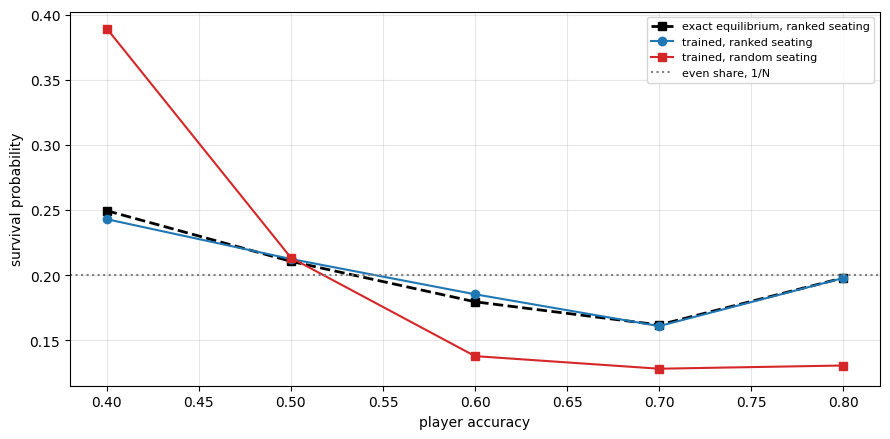

In [21]:
figure, axis = plt.subplots(figsize=(9, 4.5))
axis.plot(accuracies, [EXACT_RANKED[a] for a in accuracies], "ks--",
          label="exact equilibrium, ranked seating", linewidth=2)
axis.plot(accuracies, [ranked_survival[a] for a in accuracies], "o-",
          color="tab:blue", label="trained, ranked seating")
axis.plot(accuracies, [random_survival[a] for a in accuracies], "s-",
          color="tab:red", label="trained, random seating")
axis.axhline(UNIFORM, color="grey", linestyle=":", label="even share, 1/N")
axis.set_xlabel("player accuracy")
axis.set_ylabel("survival probability")
axis.legend(fontsize=8)
axis.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Targeting: what the two arms learned to do

Survival says the effect moved. Targeting says whether the *policy* moved with it.

In [22]:
print("%-10s %9s %9s %9s %9s %9s %10s"
      % ("seating", "0.4", "0.5", "0.6", "0.7", "0.8", "spread"))
targeting = {}
for seating in SEATINGS:
    combined = []
    for seed in SEEDS:
        combined.extend(results[(seating, seed)])
    cells = []
    values = {}
    for accuracy in accuracies:
        rate, stronger, decisions = targeting_rate(combined, accuracy=accuracy)
        values[accuracy] = rate
        cells.append(format(rate, ".4f"))
    targeting[seating] = values
    spread = max(values.values()) - min(values.values())
    print("%-10s %9s %9s %9s %9s %9s %10.4f"
          % (seating, cells[0], cells[1], cells[2], cells[3], cells[4], spread))

seating          0.4       0.5       0.6       0.7       0.8     spread
ranked        0.9999    0.3790    0.3142    0.3745    0.9998     0.6857
random        0.8855    0.9344    0.9451    0.9463    0.9353     0.0608


The two signatures step 5 built the instrument to tell apart, now side by side.

In [23]:
UNDIFFERENTIATED_BAND = 0.10

for seating in SEATINGS:
    values = targeting[seating]
    extremes = min(values[LOWEST], values[HIGHEST])
    middle = max(values[0.5], values[0.6], values[0.7])
    spread = max(values.values()) - min(values.values())
    near_half = True
    for accuracy in accuracies:
        if abs(values[accuracy] - 0.5) > UNDIFFERENTIATED_BAND:
            near_half = False

    print(seating + ":")
    print("    U-shaped (both extremes above every middle rank)?", extremes > middle)
    print("    every rank within %.2f of 0.5?                    %s"
          % (UNDIFFERENTIATED_BAND, near_half))
    print("    spread across ranks: %.4f" % spread)
    if extremes > middle:
        print("    -> the equilibrium's shape")
    elif near_half:
        print("    -> discriminates on nothing")
    else:
        print("    -> neither signature; describe it rather than labelling it")
    print()

ranked:
    U-shaped (both extremes above every middle rank)? True
    every rank within 0.10 of 0.5?                    False
    spread across ranks: 0.6857
    -> the equilibrium's shape

random:
    U-shaped (both extremes above every middle rank)? False
    every rank within 0.10 of 0.5?                    False
    spread across ranks: 0.0608
    -> neither signature; describe it rather than labelling it



## And targeting against contraction

In [24]:
print("%-10s %11s %11s %11s   %s"
      % ("seating", "5 alive", "4 alive", "3 alive", "rises?"))
for seating in SEATINGS:
    combined = []
    for seed in SEEDS:
        combined.extend(results[(seating, seed)])
    rows_alive = targeting_by_alive(combined)
    cells = []
    series = []
    for alive in [5, 4, 3]:
        if alive in rows_alive:
            cells.append(format(rows_alive[alive][0], ".4f"))
            series.append(rows_alive[alive][0])
        else:
            cells.append("no data")
            series.append(None)
    if None not in series and series[0] < series[1] < series[2]:
        mark = "yes"
    else:
        mark = "no"
    print("%-10s %11s %11s %11s   %s"
          % (seating, cells[0], cells[1], cells[2], mark))

print()
print("exact equilibrium (ranked): 0.40        0.50        1.00")
print()
print("Under random seating there is no exact equilibrium to compare against — the")
print("solver answers a fixed arrangement, and this arm has 120 of them.")

seating        5 alive     4 alive     3 alive   rises?
ranked          0.4038      0.5102      0.9763   yes
random          0.8833      0.9242      0.9662   yes

exact equilibrium (ranked): 0.40        0.50        1.00

Under random seating there is no exact equilibrium to compare against — the
solver answers a fixed arrangement, and this arm has 120 of them.


## Cross-evaluation: each arm's policy played in the other seating

The random arm's numbers above are measured under random seating, where the exact
equilibrium for ranked seating does not apply. So the gap of the random arm from 0.40 /
0.50 / 1.00 is not, on its own, evidence that it learned a different policy: the same
policy could measure differently because the seats are different.

The test that separates the two is to play each arm's trained models in the **other**
seating. If the random arm had learned the ranked equilibrium's policy, it would reproduce
the ranked arm's targeting when seated by rank. Same seeds, same measurement, 10,000
episodes per model.

In [25]:
CROSS_EPISODES = 10000
cross = {}
for trained in SEATINGS:
    for played in SEATINGS:
        combined = []
        for seed in SEEDS:
            torch.manual_seed(7000 + seed)
            game = GruelEnv(n=N_PLAYERS, reward="terminal", seating=played, seed=6000 + seed)
            combined.extend(play_episodes(game, make_agent_policy(models[(trained, seed)]),
                                          CROSS_EPISODES))
        cross[(trained, played)] = combined

print("targeting by rank, weakest -> strongest, pooled over seeds")
print("%-24s %s" % ("trained -> played in", "  ".join("%6s" % a for a in accuracies)))
for trained in SEATINGS:
    for played in SEATINGS:
        profile = targeting_profile(cross[(trained, played)])
        print("%-24s %s" % ("%s -> %s" % (trained, played),
                            "  ".join("%.4f" % profile[a] for a in accuracies)))
reference = reference_targeting[("ranked", "shoot_strongest")]
print("%-24s %s" % ("shoot_strongest, ranked", "  ".join("%.4f" % reference[a] for a in accuracies)))
print()

print("targeting by players left, played under RANKED seating, against the ranked equilibrium")
exact_alive = {5: 0.40, 4: 0.50, 3: 1.00}
for trained in SEATINGS:
    rows_alive = targeting_by_alive(cross[(trained, "ranked")])
    worst = max(abs(rows_alive[k][0] - exact_alive[k]) for k in exact_alive)
    print("  trained %-7s  5 alive %.4f   4 alive %.4f   3 alive %.4f   worst gap %.4f"
          % (trained, rows_alive[5][0], rows_alive[4][0], rows_alive[3][0], worst))
print()

random_in_ranked = targeting_profile(cross[("random", "ranked")])
distance_to_strongest = sum(abs(random_in_ranked[a] - reference[a]) for a in accuracies) / len(accuracies)
print("random-trained policy, seated by rank: %.4f from shoot_strongest" % distance_to_strongest)
if distance_to_strongest <= MATCH_THRESHOLD:
    print("-> seated by rank it plays shoot_strongest, not the ranked equilibrium: the two arms")
    print("   learned different policies, not one policy measured in two different games.")
else:
    print("-> seated by rank it is not shoot_strongest either; read the table above.")

targeting by rank, weakest -> strongest, pooled over seeds
trained -> played in        0.4     0.5     0.6     0.7     0.8
ranked -> ranked         0.9998  0.3815  0.3121  0.3706  0.9996
ranked -> random         0.5587  0.6190  0.6451  0.6336  0.6044
random -> ranked         0.9939  0.9992  0.9982  0.9967  0.9916


random -> random         0.8833  0.9325  0.9480  0.9467  0.9360
shoot_strongest, ranked  1.0000  1.0000  1.0000  1.0000  1.0000

targeting by players left, played under RANKED seating, against the ranked equilibrium
  trained ranked   5 alive 0.3979   4 alive 0.5118   3 alive 0.9763   worst gap 0.0237
  trained random   5 alive 0.9989   4 alive 0.9982   3 alive 0.9917   worst gap 0.5989

random-trained policy, seated by rank: 0.0041 from shoot_strongest
-> seated by rank it plays shoot_strongest, not the ranked equilibrium: the two arms
   learned different policies, not one policy measured in two different games.


## What this step establishes

In [26]:
print("held fixed : agent, N, reward, budget, hyperparameters, seeds")
print("moved      : seating only (%d environment attribute differs)" % len(differences))
print()
print("weakest over uniform : ranked %.3f, random %.3f"
      % (ranked_weakest / UNIFORM, random_weakest / UNIFORM))
print("closest reference    : ranked %s, random %s"
      % (closest_reference["ranked"][0], closest_reference["random"][0]))
print("targeting spread     : ranked %.4f, random %.4f"
      % (max(targeting["ranked"].values()) - min(targeting["ranked"].values()),
         max(targeting["random"].values()) - min(targeting["random"].values())))
print()
print("The exact profile was applied to the ranked arm and REFUSED for the random one,")
print("which is the discipline this step exists to demonstrate.")
print()
u_shaped = {}
for seating in SEATINGS:
    u_shaped[seating] = (
        min(arm_targeting[seating][LOWEST], arm_targeting[seating][HIGHEST])
        > max(arm_targeting[seating][0.5], arm_targeting[seating][0.6],
              arm_targeting[seating][0.7]))

ranked_is_equilibrium = u_shaped["ranked"] and matches_equilibrium["ranked"]
arms_differ = closest_reference["ranked"][0] != closest_reference["random"][0]

if ranked_is_equilibrium and arms_differ:
    print("The finding is NOT that random seating removes the weakest player's")
    print("advantage. The ranked arm shows the equilibrium's U-shape AND tracks its")
    print("contraction pattern; the random arm matches a heuristic instead. Seating")
    print("changed WHICH POLICY WAS FOUND, and the survival numbers follow from that.")
elif ranked_is_equilibrium:
    print("The ranked arm shows the equilibrium's U-shape, but both arms match the same")
    print("reference, so this measurement does not show seating changing the policy.")
else:
    print("The ranked arm does NOT show the equilibrium's U-shape, so the premise of")
    print("the comparison is missing: there is no 'found the equilibrium' arm to")
    print("contrast against. Report the two profiles and stop there.")

held fixed : agent, N, reward, budget, hyperparameters, seeds
moved      : seating only (1 environment attribute differs)

weakest over uniform : ranked 1.215, random 1.947
closest reference    : ranked neither, random shoot_strongest
targeting spread     : ranked 0.6857, random 0.0608

The exact profile was applied to the ranked arm and REFUSED for the random one,
which is the discipline this step exists to demonstrate.

The finding is NOT that random seating removes the weakest player's
advantage. The ranked arm shows the equilibrium's U-shape AND tracks its
contraction pattern; the random arm matches a heuristic instead. Seating
changed WHICH POLICY WAS FOUND, and the survival numbers follow from that.


## Reproducibility

As in step 6, **both** random streams are reset — the environment's and torch's — because
a trained policy samples its actions.

In [27]:
def measure_once():
    torch.manual_seed(7000)
    fixed_game = GruelEnv(n=N_PLAYERS, reward="terminal", seating="random", seed=9000)
    records = play_episodes(fixed_game, make_agent_policy(models[("random", 0)]), 500)
    survival = survival_by_accuracy(records, accuracies)
    rate, stronger, decisions = targeting_rate(records)
    return (tuple(round(survival[a], 10) for a in accuracies),
            round(rate, 10), decisions)


first = measure_once()
second = measure_once()

print("first :", first)
print("second:", second)
print("identical:", first == second)

first : ((0.372, 0.14, 0.136, 0.156, 0.196), 0.8242353852, 2583)
second: ((0.372, 0.14, 0.136, 0.156, 0.196), 0.8242353852, 2583)
identical: True
